# Прогноз качества вина по CRISP-DM

**Задача:** по результатам физико-химических измерений и типу вина оценить балл дегустационной комиссии. Работа выполнена на наборе [Wine Quality из Kaggle](https://www.kaggle.com/datasets/rajyellow46/wine-quality), который объединяет красное и белое португальское Vinho Verde.

Для воспроизведения запустите все ячейки по порядку в Colab или Jupyter. Ноутбук скачивает архив Kaggle без учётной записи. При локальном запуске можно положить исходный `winequalityN.csv` рядом с ноутбуком. Нужны Python 3.10+, pandas, NumPy, matplotlib и scikit-learn 1.2+.

## 1. Понимание задачи

Лаборатория контроля качества может использовать прогноз, чтобы планировать очередь образцов на дегустацию. Входные данные — результаты 11 лабораторных тестов и тип вина, доступные к моменту прогноза. Целевая переменная `quality` — порядковая оценка на шкале от 0 до 10. Решаем задачу регрессии, чтобы ошибка на один балл оценивалась мягче ошибки на три.

Основная метрика — **MAE**, средняя абсолютная ошибка в баллах. Учебный критерий успеха — MAE на отложенном тесте минимум на 10% ниже, чем у прогноза медианой обучающих оценок. Дополнительно проверим RMSE, долю прогнозов с ошибкой до одного балла включительно и результаты отдельно для белого и красного вина. Дегустационная оценка остаётся основанием для итогового решения о качестве.

In [1]:
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
TARGET = "quality"
CATEGORICAL = ["type"]
NUMERIC = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
    "pH", "sulphates", "alcohol",
]
FEATURES = CATEGORICAL + NUMERIC
TYPES = ["red", "white"]
TYPE_LABELS = {"red": "Красное", "white": "Белое"}
PALETTE = {"red": "#9A3D56", "white": "#B9842A"}

print(f"pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

pandas 3.1.1 | NumPy 2.5.5 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 2. Понимание данных

[Исходное описание UCI](https://doi.org/10.24432/C56S3T) указывает происхождение и смысл оценок. Для расчётов используем конкретный CSV из задания, поскольку в выгрузке Kaggle есть пропуски. Проверим схему, типы полей, пропуски, повторы и распределение оценок по типам вина.

In [2]:
filename = "winequalityN.csv"
local_file = Path(filename)
kaggle_api = "https://www.kaggle.com/api/v1/datasets/download/rajyellow46/wine-quality"

if local_file.is_file():
    data_bytes = local_file.read_bytes()
    source = filename
else:
    request = Request(kaggle_api, headers={"User-Agent": "wine-quality-crisp-dm-notebook/1.0"})
    with urlopen(request, timeout=60) as response:
        archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        data_bytes = archive.read(filename)
    source = "архив Kaggle"

raw = pd.read_csv(BytesIO(data_bytes))
assert set(raw.columns) == set(FEATURES + [TARGET]), "Неожиданные столбцы в CSV"
assert raw[TARGET].notna().all() and raw[TARGET].between(0, 10).all()
assert raw[TARGET].mod(1).eq(0).all(), "Оценка должна быть целой"
assert sorted(raw["type"].dropna().unique()) == TYPES and raw["type"].notna().all()
assert all(pd.api.types.is_numeric_dtype(raw[column]) for column in NUMERIC)

print(f"Источник — {source}. Строк — {len(raw):,}, признаков — {len(FEATURES)}.")
print(f"SHA-256 CSV — {sha256(data_bytes).hexdigest()}")
display(raw.head(3))

Источник — архив Kaggle. Строк — 6,497, признаков — 12.
SHA-256 CSV — cb01f91c70de066f85d4cffac3bb163e4719523861cd79ba8825b722cf98b48c


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6


Точные дубликаты — 1,168.
Строки с пропусками — 34.


,Тип,Пропуски,Уникальные значения
type,str,0,2
fixed acidity,float64,10,106
volatile acidity,float64,8,187
citric acid,float64,3,89
residual sugar,float64,2,316
chlorides,float64,2,214
free sulfur dioxide,float64,0,135
total sulfur dioxide,float64,0,276
density,float64,0,998
pH,float64,9,108


type,Красное,Белое
quality,,
3,10,20
4,53,163
5,681,1457
6,638,2198
7,199,880
8,18,175
9,0,5


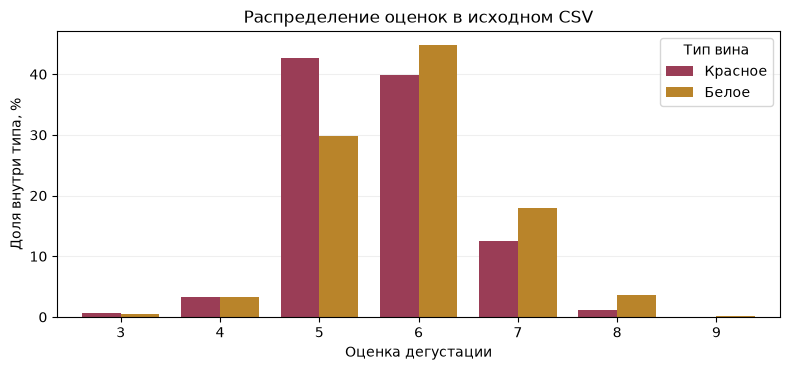

In [3]:
audit = pd.DataFrame({
    "Тип": raw.dtypes.astype(str),
    "Пропуски": raw.isna().sum(),
    "Уникальные значения": raw.nunique(),
})
print(f"Точные дубликаты — {raw.duplicated().sum():,}.")
print(f"Строки с пропусками — {raw.isna().any(axis=1).sum():,}.")
display(audit)

raw_counts = pd.crosstab(raw[TARGET], raw["type"]).reindex(columns=TYPES)
display(raw_counts.rename(columns=TYPE_LABELS))
distributions = raw_counts.div(raw_counts.sum(axis=0), axis=1) * 100
ax = distributions.rename(columns=TYPE_LABELS).plot.bar(
    color=[PALETTE[wine_type] for wine_type in TYPES], figsize=(8, 3.8),
    width=0.78,
)
ax.set(xlabel="Оценка дегустации", ylabel="Доля внутри типа, %", title="Распределение оценок в исходном CSV")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Тип вина")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Исходный CSV содержит 6 497 строк, из них 4 898 относятся к белому вину. Большая часть оценок находится около 5–6, а оценка 9 встречается всего пять раз. Средняя метрика отражает прежде всего качество работы модели на распространённых оценках. Для редких оценок отдельно покажем размер выборки и направление ошибки.

## 3. Подготовка данных

Удалим точные повторы всей строки, чтобы одинаковые записи не получали дополнительный вес. Идентификаторы образцов и партий отсутствуют, поэтому одинакова ли физическая партия у повторов, установить нельзя. Если при одинаковом наборе признаков есть несколько оценок, сохраним их как отдельные строки и поместим в один блок разбиения.

Для теста берём один заранее фиксированный блок из пяти. Страты учитывают тип вина и диапазон оценки. Объединяем крайние оценки только для разбиения, исходные баллы остаются целевой переменной. Медианы для заполнения пропусков, шкалирование и кодирование типа оцениваются внутри обучающего блока каждого разбиения через `Pipeline`.

In [4]:
clean = raw.drop_duplicates().reset_index(drop=True)
X = clean[FEATURES]
y = clean[TARGET].astype(int)
groups = pd.util.hash_pandas_object(X, index=False)
strata = X["type"].astype(str) + ":" + y.clip(lower=4, upper=8).astype(str)

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_rows, test_rows = next(outer.split(X, strata, groups=groups))
assert not set(groups.iloc[train_rows]).intersection(groups.iloc[test_rows])

X_train, X_test = X.iloc[train_rows], X.iloc[test_rows]
y_train, y_test = y.iloc[train_rows], y.iloc[test_rows]
train_groups = groups.iloc[train_rows]
inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
folds = list(inner.split(X_train, strata.iloc[train_rows], groups=train_groups))
for fit_rows, valid_rows in folds:
    assert not set(train_groups.iloc[fit_rows]).intersection(train_groups.iloc[valid_rows])

print(f"После удаления повторов — {len(clean):,} строк и {groups.nunique():,} профилей.")
print(f"Обучение — {len(X_train):,}, тест — {len(X_test):,} ({len(X_test) / len(X):.1%}).")
display(pd.DataFrame({
    "Обучение": X_train["type"].value_counts(),
    "Тест": X_test["type"].value_counts(),
}).rename(index=TYPE_LABELS))

# Описательная статистика признаков и сравнение с целью только на обучающих данных.
train_summary = X_train[NUMERIC].describe().T[["mean", "std", "min", "max"]]
train_summary["Ранговая корреляция с оценкой"] = X_train[NUMERIC].corrwith(y_train, method="spearman")
display(train_summary.round(3))

После удаления повторов — 5,329 строк и 5,329 профилей.
Обучение — 4,263, тест — 1,066 (20.0%).


,Обучение,Тест
type,,
Белое,3175,795
Красное,1088,271


,mean,std,min,max,Ранговая корреляция с оценкой
fixed acidity,7.203,1.315,3.800,15.900,-0.113
volatile acidity,0.344,0.169,0.080,1.580,-0.246
citric acid,0.318,0.146,0.000,1.660,0.110
residual sugar,5.035,4.432,0.600,31.600,-0.015
chlorides,0.057,0.038,0.009,0.611,-0.300
free sulfur dioxide,29.902,17.573,1.000,289.000,0.090
total sulfur dioxide,114.012,56.269,6.000,440.000,-0.050
density,0.995,0.003,0.987,1.010,-0.341
pH,3.226,0.159,2.720,3.900,0.057
sulphates,0.533,0.151,0.220,2.000,0.029


## 4. Моделирование

Сравним три варианта с медианным прогнозом: линейную Ridge-регрессию, случайный лес и градиентный бустинг по гистограммам. Линейная модель даёт ориентир для аддитивной зависимости. Деревья могут учитывать нелинейные связи между лабораторными показателями. Используем одинаковые четыре блока кросс-валидации для всех кандидатов и выбираем по среднему MAE. Финальный тест для выбора модели и параметров не используется.

In [5]:
def preprocessing(scale):
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("chemical", Pipeline(numeric_steps), NUMERIC),
        ("wine_type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])

candidates = {
    "Медианный прогноз": (
        DummyRegressor(strategy="median"), False, {},
    ),
    "Ridge": (
        Ridge(), True, {"model__alpha": [0.1, 1.0, 10.0]},
    ),
    "Случайный лес": (
        RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1),
        False,
        {"model__min_samples_leaf": [2, 5], "model__max_features": [0.7, 1.0]},
    ),
    "Градиентный бустинг": (
        HistGradientBoostingRegressor(max_iter=220, early_stopping=False, random_state=SEED),
        False,
        {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31]},
    ),
}

searches = {}
validation_results = []
for name, (estimator, scale, grid) in candidates.items():
    pipeline = Pipeline([("prepare", preprocessing(scale)), ("model", estimator)])
    search = GridSearchCV(
        pipeline, param_grid=grid, scoring="neg_mean_absolute_error", cv=folds,
        n_jobs=2, refit=True, error_score="raise",
    )
    search.fit(X_train, y_train)
    searches[name] = search
    validation_results.append({
        "Модель": name,
        "MAE CV": -search.best_score_,
        "Ст. отклонение MAE": search.cv_results_["std_test_score"][search.best_index_],
        "Параметры": {key.removeprefix("model__"): value for key, value in search.best_params_.items()},
    })

leaderboard = pd.DataFrame(validation_results).set_index("Модель").sort_values("MAE CV")
selected_name = leaderboard.index[0]
fitted_model = searches[selected_name].best_estimator_
baseline = searches["Медианный прогноз"].best_estimator_
display(leaderboard.round(4))
print(f"Выбор по CV — {selected_name}.")

,MAE CV,Ст. отклонение MAE,Параметры
Модель,,,
Случайный лес,0.5422,0.0055,"{'max_features': 0.7, 'min_samples_leaf': 2}"
Градиентный бустинг,0.5497,0.0071,"{'learning_rate': 0.05, 'max_leaf_nodes': 15}"
Ridge,0.5716,0.0069,{'alpha': 10.0}
Медианный прогноз,0.6425,0.0019,{}


Выбор по CV — Случайный лес.


## 5. Оценка

На отложенных строках проверим выбранную модель и медианный прогноз. Приведём MAE, RMSE и долю ошибок в пределах одного балла без округления предсказаний. Для интерпретации посмотрим, насколько ошибка зависит от типа вина и насколько прогноз смещён для низких и высоких фактических оценок.

In [6]:
prediction = np.clip(fitted_model.predict(X_test), 0, 10)
baseline_prediction = baseline.predict(X_test)

def metrics(y_true, y_pred):
    return {
        "Образцы": len(y_true),
        "MAE, баллы": mean_absolute_error(y_true, y_pred),
        "RMSE, баллы": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Ошибка ≤ 1 балла, %": 100 * np.mean(np.abs(y_true - y_pred) <= 1),
    }

holdout = pd.DataFrame([
    metrics(y_test, baseline_prediction), metrics(y_test, prediction),
], index=["Медианный прогноз", f"Выбрано: {selected_name}"])
display(holdout.round(3))

by_type = []
for wine_type in TYPES:
    mask = X_test["type"].eq(wine_type).to_numpy()
    base = metrics(y_test[mask], baseline_prediction[mask])
    selected = metrics(y_test[mask], prediction[mask])
    by_type.append({
        "Вино": TYPE_LABELS[wine_type], "MAE медианы": base["MAE, баллы"], **selected,
    })
display(pd.DataFrame(by_type).set_index("Вино").round(3))

base_mae, model_mae = holdout["MAE, баллы"].to_numpy()
gain = 100 * (1 - model_mae / base_mae)
verdict = "Критерий успеха выполнен." if gain >= 10 else "Критерий успеха не выполнен."
display(Markdown(
    f"**Результат на тесте.** MAE модели «{selected_name}» — **{model_mae:.3f}** "
    f"при **{base_mae:.3f}** у медианного прогноза. "
    f"Относительное снижение MAE составило **{gain:.1f}%**. {verdict}"
))

,Образцы,"MAE, баллы","RMSE, баллы","Ошибка ≤ 1 балла, %"
Медианный прогноз,1066,0.645,0.910,92.589
Выбрано: Случайный лес,1066,0.508,0.673,89.024


,MAE медианы,Образцы,"MAE, баллы","RMSE, баллы","Ошибка ≤ 1 балла, %"
Вино,,,,,
Красное,0.672,271,0.465,0.616,91.513
Белое,0.636,795,0.522,0.692,88.176


**Результат на тесте.** MAE модели «Случайный лес» — **0.508** при **0.645** у медианного прогноза. Относительное снижение MAE составило **21.4%**. Критерий успеха выполнен.

Случайный лес выигрывает по MAE и RMSE, а медианный прогноз чаще попадает в интервал ±1 балл. Здесь важна граница метрики. Медиана равна 6 и засчитывает все оценки 5, 6 и 7, а числовой прогноз, например 6,01 при оценке 5, уже выходит за границу. Если для лаборатории критична именно доля попаданий в один балл, её следует сделать основной метрикой и повторить выбор модели с новой процедурой оценки.

,Образцы,Средний_прогноз,Смещение,MAE
Фактический балл,,,,
3,8,5.320,2.320,2.320
4,39,5.240,1.240,1.240
5,350,5.396,0.396,0.416
6,466,5.928,-0.072,0.354
7,171,6.328,-0.672,0.681
8,31,6.580,-1.420,1.420
9,1,5.619,-3.381,3.381


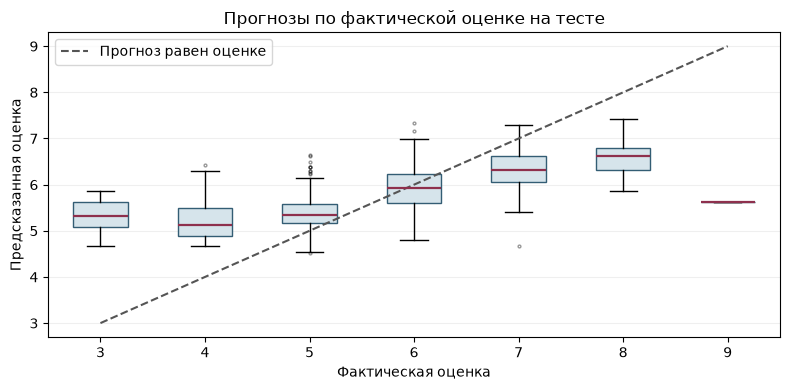

Для оценки 3 средний прогноз равен 5.32 (n = 8), для оценки 9 — 5.62 (n = 1). При таком числе крайних оценок нужен отдельный набор для надёжной проверки редких случаев.

In [7]:
errors = pd.DataFrame({
    "Фактический балл": y_test.to_numpy(),
    "Прогноз": prediction,
    "Ошибка со знаком": prediction - y_test.to_numpy(),
    "Абсолютная ошибка": np.abs(prediction - y_test.to_numpy()),
})
by_score = errors.groupby("Фактический балл").agg(
    Образцы=("Прогноз", "size"),
    Средний_прогноз=("Прогноз", "mean"),
    Смещение=("Ошибка со знаком", "mean"),
    MAE=("Абсолютная ошибка", "mean"),
)
display(by_score.round(3))

scores = by_score.index.to_numpy()
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(
    [errors.loc[errors["Фактический балл"].eq(score), "Прогноз"] for score in scores],
    positions=scores, widths=0.52, patch_artist=True,
    boxprops={"facecolor": "#D6E4EB", "edgecolor": "#335D74"},
    medianprops={"color": "#8E304D", "linewidth": 1.6},
    flierprops={"markersize": 2, "alpha": 0.4},
)
ax.plot(scores, scores, color="#555555", linestyle="--", label="Прогноз равен оценке")
ax.set(xlabel="Фактическая оценка", ylabel="Предсказанная оценка",
       title="Прогнозы по фактической оценке на тесте")
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

low = by_score.iloc[0]
high = by_score.iloc[-1]
display(Markdown(
    f"Для оценки {scores[0]} средний прогноз равен {low['Средний_прогноз']:.2f} "
    f"(n = {int(low['Образцы'])}), для оценки {scores[-1]} — "
    f"{high['Средний_прогноз']:.2f} (n = {int(high['Образцы'])}). "
    "При таком числе крайних оценок нужен отдельный набор для надёжной проверки редких случаев."
))

In [8]:
# Описательная интерпретация уже выбранной модели. Тест не влияет на обучение.
permutation = permutation_importance(
    fitted_model, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=5, random_state=SEED, n_jobs=2,
)
impact = pd.DataFrame({
    "Признак": FEATURES,
    "Рост MAE при перестановке": permutation.importances_mean,
}).set_index("Признак").sort_values("Рост MAE при перестановке", ascending=False)
display(impact.head(6).round(3))

,Рост MAE при перестановке
Признак,
alcohol,0.146
volatile acidity,0.068
free sulfur dioxide,0.041
sulphates,0.018
total sulfur dioxide,0.014
pH,0.013


Перестановка показывает, какие столбцы помогают выбранной модели на тесте. Для взаимосвязанных измерений важность может распределяться между несколькими столбцами. Эту таблицу нельзя использовать как доказательство причинного влияния вещества на качество.

Данные относятся к Vinho Verde. В выгрузке нет идентификаторов производителей, времени и партий, поэтому проверка отражает перенос на другие профили из того же набора. Для применения в лаборатории нужна отдельная проверка на новых партиях и на винах того же профиля производства.

## 6. Внедрение

Ниже функция для пакетной оценки новых образцов. Она проверяет входную схему, код типа вина и числовые значения. Подготовка признаков выполняется тем же обученным пайплайном. В пилоте вместе с прогнозом следует сохранять версию модели, тип вина и долю пропущенных измерений, а после дегустации — фактический балл. Сравнивать MAE с медианным ориентиром отдельно по типам вина и пересматривать модель при устойчивом ухудшении.

In [9]:
def predict_quality(samples):
    """Оценить новые образцы по типу вина и 11 лабораторным показателям."""
    if samples.empty:
        raise ValueError("Нужен хотя бы один образец.")
    missing_columns = [column for column in FEATURES if column not in samples.columns]
    if missing_columns:
        raise ValueError(f"Отсутствуют столбцы: {', '.join(missing_columns)}")

    features = samples.loc[:, FEATURES].copy()
    if not features["type"].isin(TYPES).all():
        raise ValueError("Тип вина должен иметь значение red или white.")
    for column in NUMERIC:
        features[column] = pd.to_numeric(features[column], errors="raise").astype(float)
    if np.isinf(features[NUMERIC].to_numpy(dtype=float)).any():
        raise ValueError("Измерения должны быть конечными числами или пропусками.")
    if features[NUMERIC].isna().all(axis=1).any():
        raise ValueError("Для каждого образца нужно хотя бы одно лабораторное измерение.")

    values = np.clip(fitted_model.predict(features), 0, 10)
    return pd.Series(values, index=samples.index, name="Прогноз качества")

example = X_test.iloc[:3]
example_predictions = predict_quality(example)
assert np.allclose(example_predictions.to_numpy(), prediction[:len(example)])
display(pd.DataFrame({
    "Тип": example["type"].map(TYPE_LABELS),
    "Прогноз качества": example_predictions.round(2),
    "Оценка дегустации": y_test.loc[example.index],
}))

,Тип,Прогноз качества,Оценка дегустации
9,Белое,6.98,7
18,Белое,6.35,8
24,Белое,5.73,6


### Источники

- rajyellow46. *Wine Quality*. Выгрузка из задания. [Kaggle](https://www.kaggle.com/datasets/rajyellow46/wine-quality)
- Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. *Wine Quality*. 2009. [UCI Machine Learning Repository](https://doi.org/10.24432/C56S3T)
- IBM. *CRISP-DM Help Overview*. [Описание методологии](https://www.ibm.com/docs/en/spss-modeler/saas?topic=dm-crisp-help-overview)